In [2]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.rl.analysis import runs as R, models as M, data as D
import src.rl.evaluate_sarsa_models as sarsa_eval

R.set_path_mappings([("/rds/general/user/jormond/home/projects/ai_clinician",
                      "/home/jake/Documents/AI_Clinician/models")])


[('/rds/general/user/jormond/home/projects/ai_clinician',
  '/home/jake/Documents/AI_Clinician/models')]

# SARSA

In [3]:
basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
sarsa_old_dir = os.path.join(basic_q_dir, "with_actions", "health_score_change_only", "five_seeds")
sarsa_new_dir = os.path.join(basic_q_dir, "with_actions", "health_score_change_only", "five_seeds_1000_epochs")

sarsa_old = M.load_study_models(R.make_study(sarsa_old_dir, family="sarsa", group_by=()))[()]
sarsa_new = M.load_study_models(R.make_study(sarsa_new_dir, family="sarsa", group_by=()))[()]
assert sorted(sarsa_old) == sorted(sarsa_new) == [0, 1, 2, 3, 4]

store = D.DataStore(keep=("train", "val"))

  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/five_seeds:
    vaso_reward_coefficient: saved=0.01 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  loaded LoadedModel(seed 0: critic)
  loaded LoadedModel(seed 1: critic)
  loaded LoadedModel(seed 2: critic)
  loaded LoadedModel(seed 3: critic)
  loaded LoadedModel(seed 4: critic)
  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/five_seeds_1000_epochs:
    vaso_reward_coefficient: saved=0.01 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  loaded LoadedModel(seed 0: critic)
  loaded LoadedModel(seed 1: critic)
  loaded LoadedModel(seed 2: critic

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train, val)


using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 0: gap old -0.737 -> new -0.059   mean TD +0.0216 -> +0.0051   corr(Q) 0.67
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 1: gap old -0.672 -> new -0.400   mean TD +0.0203 -> +0.0136   corr(Q) 0.50
  building processors for state seed 2, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using

,seed,critic,mean_td,median_td,rmse_td,huber_td,gap_interior,gap_interior_lo,gap_interior_hi,corr_interior,Q_interior_mean,G_interior_mean,H_interior
0,0,old,0.0216,0.0367,0.6828,0.1847,-0.7367,-0.9047,-0.5627,0.1798,-0.0788,0.6579,119
1,0,new,0.0051,0.0213,0.7716,0.2098,-0.0594,-0.2700,0.1362,0.1803,0.5985,0.6579,119
2,1,old,0.0203,0.0355,0.7026,0.1934,-0.6720,-0.8545,-0.4847,0.1441,-0.0141,0.6579,119
3,1,new,0.0136,0.0283,0.8046,0.2258,-0.3995,-0.6016,-0.2097,0.0627,0.2584,0.6579,119
4,2,old,0.0178,0.0350,0.6943,0.1884,-0.5624,-0.7423,-0.3871,0.1403,0.0956,0.6579,119
5,2,new,0.0093,0.0255,0.8011,0.2222,-0.1848,-0.3798,0.0100,0.1300,0.4731,0.6579,119
6,3,old,0.0190,0.0325,0.6934,0.1897,-0.6173,-0.7892,-0.4439,0.2230,0.0406,0.6579,119
7,3,new,0.0130,0.0294,0.7506,0.2064,-0.3208,-0.5094,-0.1402,0.2319,0.3371,0.6579,119
8,4,old,0.0190,0.0348,0.6869,0.1866,-0.6105,-0.8114,-0.4088,0.0933,0.0474,0.6579,119
9,4,new,0.0191,0.0335,0.8386,0.2304,-0.5856,-0.8245,-0.3552,0.1139,0.0723,0.6579,119


,seed,corr_q
0,0,0.675
1,1,0.502
2,2,0.463
3,3,0.608
4,4,0.516


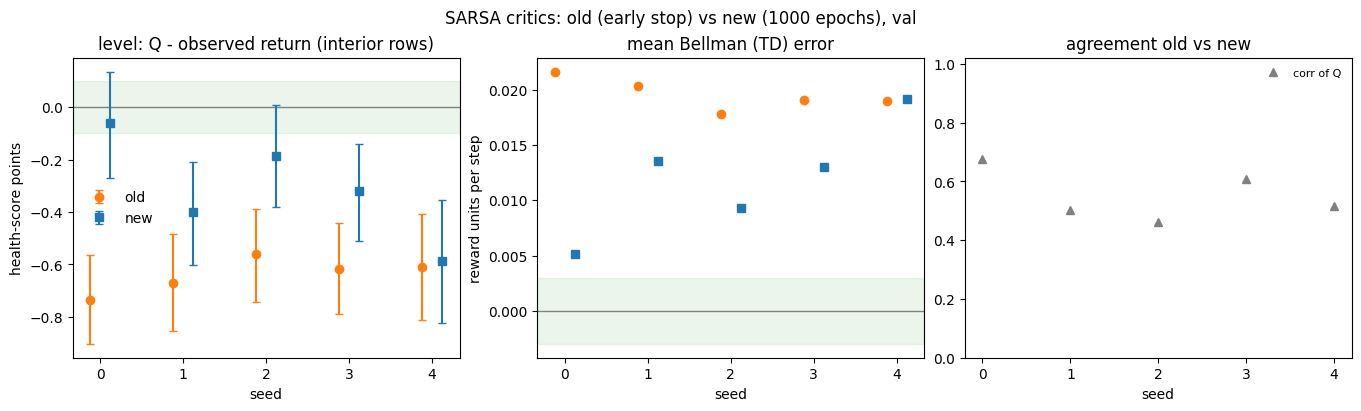

In [4]:
per_critic, per_seed = sarsa_eval.compare_sarsa_critics(sarsa_old, sarsa_new, store, split="val")
display(per_critic.round(4)); display(per_seed.round(3))
sarsa_eval.plot_sarsa_comparison(per_critic, per_seed, title="SARSA critics: old (early stop) vs new (1000 epochs), val");

# CQL

In [7]:
import src.rl.evaluate_models_n_epochs as ne

In [8]:
ALPHA = 0.029
cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
cql_old_dir = os.path.join(cql_model_dir, "with_actions", "health_score_change_only", "alpha_sweep")
cql_new_dir = os.path.join(cql_model_dir, "with_actions", "health_score_change_only", "fixed_alpha_1000_epochs")

is_alpha = lambda r: np.isclose(float(r.get("cql_alpha")), ALPHA)
cql_old = M.load_study_models(R.make_study(cql_old_dir, family="cql", group_by=(), include=is_alpha))[()]
cql_new = M.load_study_models(R.make_study(cql_new_dir, family="cql", group_by=(), include=is_alpha))[()]
assert sorted(cql_old) == sorted(cql_new) == [0, 1, 2, 3, 4]

  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/alpha_sweep:
    vaso_reward_coefficient: saved=0.1 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  loaded LoadedModel(seed 0: actor, critic)
  loaded LoadedModel(seed 1: actor, critic)
  loaded LoadedModel(seed 2: actor, critic)
  loaded LoadedModel(seed 3: actor, critic)
  loaded LoadedModel(seed 4: actor, critic)
  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/fixed_alpha_1000_epochs:
    vaso_reward_coefficient: saved=0.1 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  loaded LoadedModel(seed 0: actor, critic)
  loaded L

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 0: gap old -0.737 -> new -0.059   mean TD +0.0216 -> +0.0051   corr(Q) 0.67   adv_norm 0.224 -> 0.076   corr(adv) 0.78
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: train, val)
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
  seed 1: gap old -0.672 -> new -0.400   mean TD +0.0203 -> +0.0136   corr(Q) 0.50

,seed,critic,mean_td,median_td,rmse_td,huber_td,gap_interior,gap_interior_lo,gap_interior_hi,corr_interior,Q_interior_mean,G_interior_mean,H_interior,adv_all_norm,frac_adv_pos,adv_all_norm_lo,adv_all_norm_hi
0,0,old,0.0216,0.0367,0.6828,0.1847,-0.7367,-0.9047,-0.5627,0.1798,-0.0788,0.6579,119,0.2239,0.7154,0.1975,0.2499
1,0,new,0.0051,0.0213,0.7716,0.2098,-0.0594,-0.2700,0.1362,0.1803,0.5985,0.6579,119,0.0761,0.7114,0.0657,0.0849
2,1,old,0.0203,0.0355,0.7026,0.1934,-0.6720,-0.8545,-0.4847,0.1441,-0.0141,0.6579,119,0.2124,0.7513,0.1910,0.2352
3,1,new,0.0136,0.0283,0.8046,0.2258,-0.3995,-0.6016,-0.2097,0.0627,0.2584,0.6579,119,0.0970,0.7460,0.0867,0.1077
4,2,old,0.0178,0.0350,0.6943,0.1884,-0.5624,-0.7423,-0.3871,0.1403,0.0956,0.6579,119,0.1290,0.6864,0.1068,0.1492
5,2,new,0.0093,0.0255,0.8011,0.2222,-0.1848,-0.3798,0.0100,0.1300,0.4731,0.6579,119,0.0428,0.6826,0.0336,0.0512
6,3,old,0.0190,0.0325,0.6934,0.1897,-0.6173,-0.7892,-0.4439,0.2230,0.0406,0.6579,119,0.2627,0.7663,0.2353,0.2873
7,3,new,0.0130,0.0294,0.7506,0.2064,-0.3208,-0.5094,-0.1402,0.2319,0.3371,0.6579,119,0.0915,0.7675,0.0823,0.1000
8,4,old,0.0190,0.0348,0.6869,0.1866,-0.6105,-0.8114,-0.4088,0.0933,0.0474,0.6579,119,0.2583,0.7739,0.2330,0.2864
9,4,new,0.0191,0.0335,0.8386,0.2304,-0.5856,-0.8245,-0.3552,0.1139,0.0723,0.6579,119,0.0748,0.7634,0.0638,0.0864


,seed,corr_q,corr_adv,sign_agree,adv_norm_old,adv_norm_new,d_adv_norm,d_adv_norm_lo,d_adv_norm_hi
0,0,0.675,0.777,0.954,0.224,0.076,-0.148,-0.166,-0.130
1,1,0.502,0.781,0.946,0.212,0.097,-0.115,-0.131,-0.102
2,2,0.463,0.722,0.943,0.129,0.043,-0.086,-0.101,-0.071
3,3,0.608,0.799,0.942,0.263,0.091,-0.171,-0.189,-0.152
4,4,0.516,0.687,0.930,0.258,0.075,-0.184,-0.205,-0.161


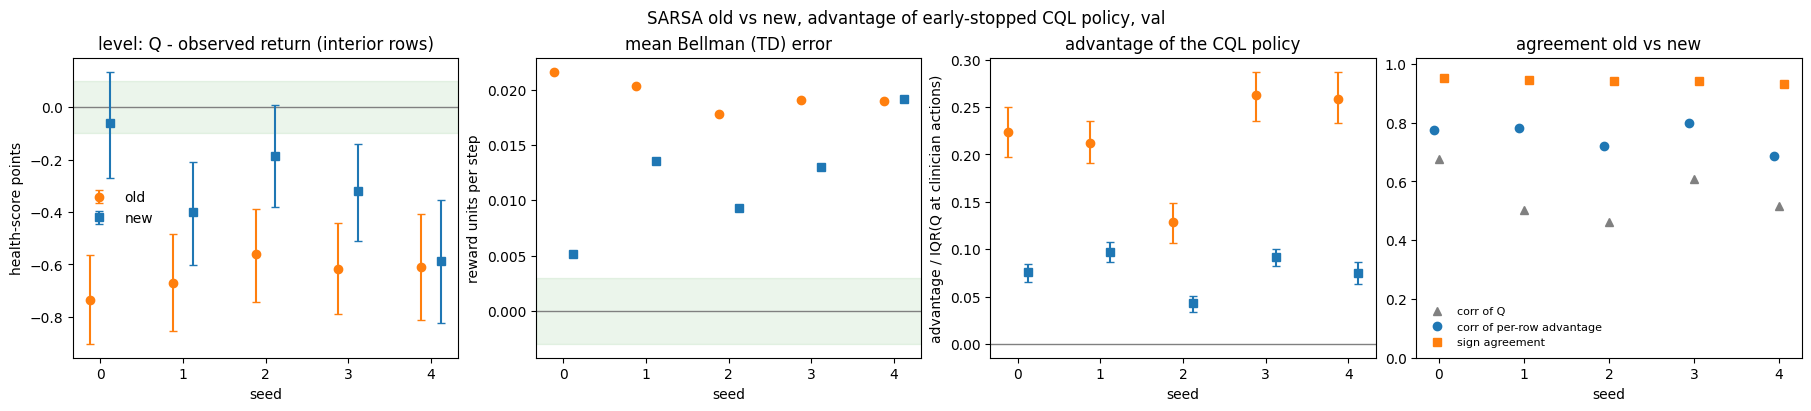

In [9]:
per_critic, per_seed = sarsa_eval.compare_sarsa_critics(sarsa_old, sarsa_new, store, split="val", cql_models=cql_old)
display(per_critic.round(4)); display(per_seed.round(3))
sarsa_eval.plot_sarsa_comparison(per_critic, per_seed, title="SARSA old vs new, advantage of early-stopped CQL policy, val");

  seed 0 judged by sarsa_old: advantage old +0.224 -> new +0.142 (d -0.082 [-0.099, -0.065])
  seed 0 judged by sarsa_new: advantage old +0.076 -> new +0.050 (d -0.026 [-0.032, -0.020])
  seed 1 judged by sarsa_old: advantage old +0.212 -> new +0.067 (d -0.146 [-0.170, -0.125])
  seed 1 judged by sarsa_new: advantage old +0.097 -> new +0.038 (d -0.059 [-0.069, -0.049])
  seed 2 judged by sarsa_old: advantage old +0.129 -> new +0.091 (d -0.038 [-0.053, -0.023])
  seed 2 judged by sarsa_new: advantage old +0.043 -> new +0.034 (d -0.008 [-0.013, -0.002])
  seed 3 judged by sarsa_old: advantage old +0.263 -> new +0.094 (d -0.169 [-0.188, -0.149])
  seed 3 judged by sarsa_new: advantage old +0.091 -> new +0.036 (d -0.056 [-0.062, -0.049])
  seed 4 judged by sarsa_old: advantage old +0.258 -> new +0.114 (d -0.144 [-0.175, -0.117])
  seed 4 judged by sarsa_new: advantage old +0.075 -> new +0.040 (d -0.034 [-0.043, -0.026])


,seed,judge,adv_old,adv_old_lo,adv_old_hi,frac_pos_old,adv_new,adv_new_lo,adv_new_hi,frac_pos_new,d_adv,d_adv_lo,d_adv_hi
0,0,sarsa_old,0.224,0.197,0.250,0.715,0.142,0.118,0.167,0.639,-0.082,-0.099,-0.065
1,0,sarsa_new,0.076,0.066,0.085,0.711,0.050,0.041,0.059,0.632,-0.026,-0.032,-0.020
2,1,sarsa_old,0.212,0.191,0.235,0.751,0.067,0.048,0.084,0.588,-0.146,-0.170,-0.125
3,1,sarsa_new,0.097,0.087,0.108,0.746,0.038,0.028,0.050,0.578,-0.059,-0.069,-0.049
4,2,sarsa_old,0.129,0.107,0.149,0.686,0.091,0.071,0.110,0.577,-0.038,-0.053,-0.023
5,2,sarsa_new,0.043,0.034,0.051,0.683,0.034,0.025,0.044,0.573,-0.008,-0.013,-0.002
6,3,sarsa_old,0.263,0.235,0.287,0.766,0.094,0.070,0.115,0.574,-0.169,-0.188,-0.149
7,3,sarsa_new,0.091,0.082,0.100,0.767,0.036,0.027,0.044,0.577,-0.056,-0.062,-0.049
8,4,sarsa_old,0.258,0.233,0.286,0.774,0.114,0.089,0.139,0.620,-0.144,-0.175,-0.117
9,4,sarsa_new,0.075,0.064,0.086,0.763,0.040,0.028,0.053,0.613,-0.034,-0.043,-0.026


,seed,fluid_clin,fluid_old,fluid_new,fluid_absdiff,fluid_corr,vaso_clin,vaso_old,vaso_new,vaso_absdiff,vaso_corr
0,0,0.496,0.352,0.399,0.099,0.809,0.021,0.005,0.012,0.012,0.402
1,1,0.496,0.336,0.453,0.150,0.644,0.021,0.006,0.009,0.009,0.537
2,2,0.496,0.395,0.430,0.097,0.797,0.021,0.006,0.010,0.010,0.520
3,3,0.496,0.320,0.436,0.131,0.765,0.021,0.005,0.014,0.013,0.607
4,4,0.496,0.322,0.424,0.141,0.678,0.021,0.007,0.009,0.009,0.560


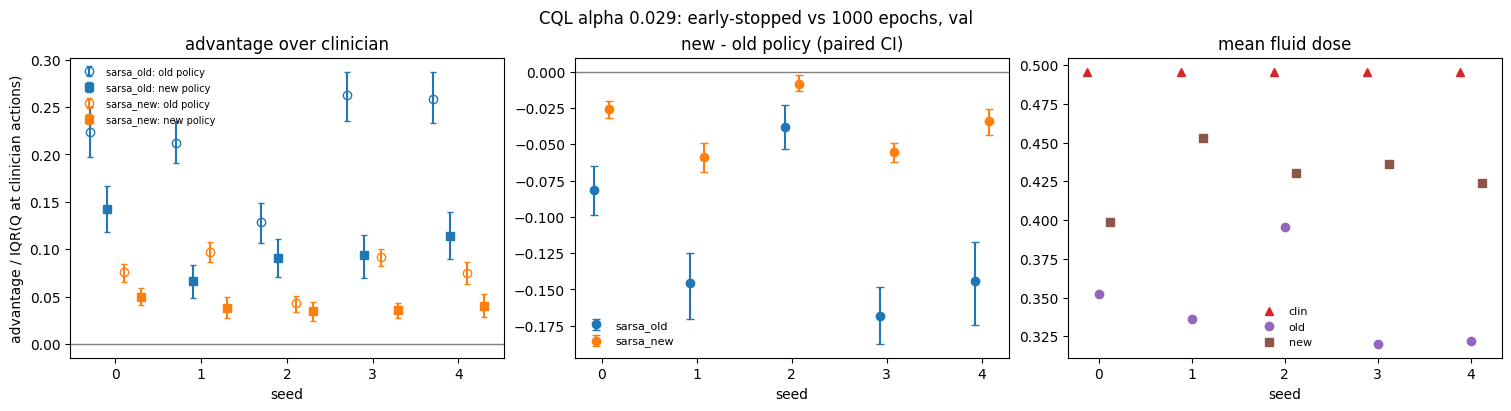

In [10]:
adv, acts = ne.compare_cql_policies(cql_old, cql_new, {"sarsa_old": sarsa_old, "sarsa_new": sarsa_new}, store, split="val")
display(adv.round(3)); display(acts.round(3))
ne.plot_cql_comparison(adv, acts, title="CQL alpha 0.029: early-stopped vs 1000 epochs, val");

,set,dim,n_seeds,pearson_mean,pearson_min,spearman_mean,jaccard_on_mean,jaccard_on_min,mean_sd_across_seeds,all_agree_on_off,any_on
0,early_stopped,fluid,5,0.801,0.718,0.813,0.856,0.846,0.077,0.750,0.899
1,early_stopped,vaso,5,0.537,0.469,0.496,0.340,0.282,0.005,0.918,0.089
2,1000_epochs,fluid,5,0.695,0.663,0.719,0.889,0.876,0.089,0.794,0.935
3,1000_epochs,vaso,5,0.449,0.363,0.321,0.238,0.159,0.011,0.639,0.371


,set,dim,seed,mean_dose,share_on
0,early_stopped,fluid,0,0.3524,0.7696
1,early_stopped,fluid,1,0.3359,0.7859
2,early_stopped,fluid,2,0.3955,0.8243
3,early_stopped,fluid,3,0.3199,0.7573
4,early_stopped,fluid,4,0.3221,0.7843
5,early_stopped,vaso,0,0.0048,0.0345
6,early_stopped,vaso,1,0.0064,0.0474
7,early_stopped,vaso,2,0.0057,0.0444
8,early_stopped,vaso,3,0.0051,0.0306
9,early_stopped,vaso,4,0.0070,0.0424


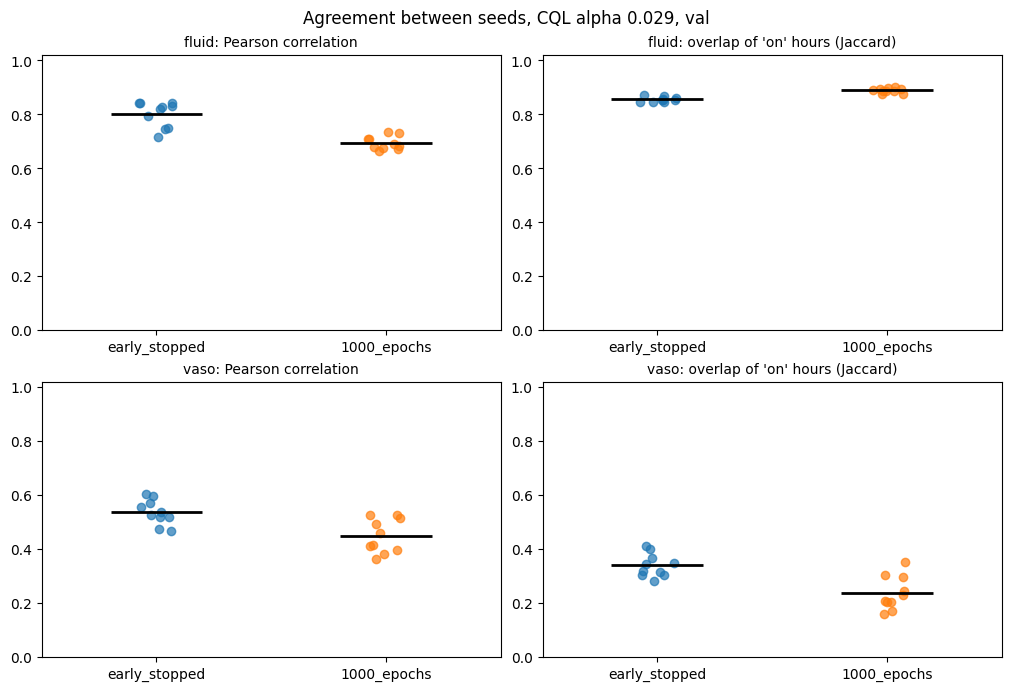

In [11]:
pairs, per_seed_dose, cons = ne.policy_consistency(
    {"early_stopped": cql_old, "1000_epochs": cql_new}, store, split="val")
display(cons.round(3)); display(per_seed_dose.round(4))
ne.plot_policy_consistency(pairs, title="Agreement between seeds, CQL alpha 0.029, val");

In [12]:
ov = ne.overlap_by_threshold({"early_stopped": cql_old, "1000_epochs": cql_new}, store, dim="vaso",
                             thresholds=(0.005, 0.01, 0.02, 0.05, 0.1), split="val")
display(ov.round(3))

,set,threshold,share_on,any_on,jaccard_on,jaccard_chance,dose_corr_both_on,n_both_on
0,early_stopped,0.005,0.040,0.089,0.340,0.020,0.472,1829.9
1,early_stopped,0.010,0.040,0.089,0.340,0.020,0.472,1829.9
2,early_stopped,0.020,0.040,0.089,0.340,0.020,0.472,1829.9
3,early_stopped,0.050,0.040,0.089,0.340,0.020,0.472,1829.9
4,early_stopped,0.100,0.036,0.082,0.335,0.018,0.412,1642.0
5,1000_epochs,0.005,0.146,0.371,0.238,0.072,0.634,5145.8
6,1000_epochs,0.010,0.146,0.371,0.238,0.072,0.634,5145.8
7,1000_epochs,0.020,0.146,0.371,0.238,0.072,0.634,5145.8
8,1000_epochs,0.050,0.061,0.171,0.214,0.031,0.531,1945.4
9,1000_epochs,0.100,0.024,0.067,0.232,0.012,0.254,815.3
